# Ансамблевые методы: прогнозирование оттока клиентов

## Титульный лист

**Дисциплина:** Машинное обучение и ИИ  
**Модуль 3:** Ансамблевые методы (базовый и продвинутый уровень)  
**Датасет:** *Telco Customer Churn*

**Выполнил:** Белозёров Константин Сергеевич  
**Группа:** ПКТб-23-1  
**Преподаватель:** не указан в задании

**Ссылка на репозиторий:** https://github.com/Pankyxa/ML_Spirin  
**Путь к модулю:** `module-3-churn/notebook.ipynb`  
**Дата сдачи:** 2026-11-02

*Ноутбук подготовлен с помощью ИИ-ассистента Cursor. Метрики посчитаны на `telco_churn.csv`.*


## Введение

**Задача.** Нужно заранее понять, уйдёт ли клиент телеком-компании. Это бинарная классификация: `Churn = 1` — уйдёт, `0` — останется. Таких клиентов 26.5%, остальные 73.5% пока остаются.

**Ансамбль** — это не одна модель, а несколько, чьи ответы складываются. Случайный лес усредняет деревья, обученные на разных кусках выборки. Бустинг строит следующее дерево там, где предыдущие ошиблись. Одиночное дерево на этих данных легко запоминает редкие комбинации услуг. Набор моделей ошибается меньше, потому что случайные промахи не совпадают.

**Почему не одна логистическая регрессия.** Контракт, срок жизни и набор услуг связаны нелинейно: волокно опасно в основном для месячных новичков, а не для всех подряд. Ансамбль умеет такие развилки. Цена — больше времени на обучение и менее прямые коэффициенты, поэтому рядом нужен SHAP.

**Метрика.** Accuracy здесь лукавит: модель «никто не уйдёт» уже получает 73.5%. Важнее поймать тех, кто уйдёт, и не завалить отдел удержания ложными тревогами. Сравнивать модели удобнее по **ROC-AUC**: она не привязана к порогу 0.5. F1 остаётся контролем уже на конкретных метках.

**Цель работы:**

1. Обучить Random Forest, XGBoost, LightGBM и CatBoost и сравнить их.
2. Подобрать гиперпараметры лучшей бустинг-модели через Optuna.
3. Разобрать её через SHAP.


## Теоретическая часть

### Ансамбль

Одна модель видит данные под одним углом. Если этот угол неудачный, ошибка повторяется на всех похожих клиентах. Ансамбль собирает несколько таких углов. Пока ошибки разных моделей не совпадают, среднее или сумма оказывается ближе к правде, чем любой участник по отдельности. За это платят временем и тем, что «почему модель так решила» уже не читается одним коэффициентом.

### Bagging и boosting

Бэггинг учит модели параллельно и почти независимо: каждая получает свою бутстрэп-выборку и часто случайный набор столбцов. Итог — среднее. Бустинг учит модели очередью. Следующая смотрит на остатки предыдущих и добавляет поправку с небольшим шагом `learning_rate`.

$$H(x) = \frac{1}{M} \sum_{i=1}^{M} h_i(x) \quad \text{(Bagging)}$$

$$H(x) = \sum_{i=1}^{M} \alpha_i \cdot h_i(x) \quad \text{(Boosting)}$$

Бэггинг хорошо снижает разброс. Бустинг снижает и смещение, но без ограничения глубины и числа деревьев начинает учить шум.

### Random Forest

Лес — бэггинг деревьев плюс случайный набор признаков в каждом расщеплении. Деревья получаются разными, даже если выборка одна и та же. Глубина и `min_samples_leaf` не дают отдельному дереву запомнить клиента. `class_weight='balanced'` штрафует пропуск ушедшего сильнее, чем пропуск оставшегося: ушедших в таблице меньше.

### Градиентный бустинг

XGBoost, LightGBM и CatBoost строят деревья по очереди и минимизируют логистическую потерю. XGBoost — самый привычный вариант с явной регуляризацией. LightGBM растит дерево по листьям, а не по уровням, и на больших таблицах обычно быстрее. CatBoost специально обрабатывает категории и меньше зависит от того, в каком порядке они закодированы. Здесь категории заранее переведены в числа, чтобы все четыре модели ели одну матрицу. `scale_pos_weight` у XGBoost и `class_weight` у LightGBM компенсируют долю ушедших 26.5%.

### Optuna

Перебор сеткой проверяет заранее заданные точки. Optuna предлагает следующую точку, глядя на уже посчитанные. Это байесовский поиск: меньше пустых прогонов, чем у полного GridSearch. Внутри каждого испытания качество — средний ROC-AUC на 5 стратифицированных фолдах обучающей части. Тест в подбор не входит.

### SHAP

SHAP раздаёт прогноз между признаками так, как значения Шепли раздают выигрыш между игроками. Вклад признака — насколько в среднем меняется прогноз, если этот признак добавить к разным наборам остальных. Summary plot показывает это по всей выборке, waterfall — по одному клиенту, dependence — как вклад меняется вместе со значением признака.

| Модель | Идея | Сильная сторона | Слабое место |
|--------|------|-----------------|--------------|
| Random Forest | параллельные деревья | устойчив, мало настроек | хуже ловит тонкие взаимодействия |
| XGBoost | бустинг по уровням | точный, есть регуляризация | дольше LightGBM |
| LightGBM | бустинг по листьям | быстрый | чувствителен к `num_leaves` |
| CatBoost | бустинг с категориями | устойчив к кодировке | дольше на маленькой таблице |


## Описание данных

**Источник:** [Telco Customer Churn](https://www.kaggle.com/datasets/blastchar/telco-customer-churn)

- Записей: 7043
- Признаков: 19, плюс `customerID` и цель `Churn`
- Числовых полей в сырой таблице: `tenure`, `MonthlyCharges`, `SeniorCitizen`; `TotalCharges` записан текстом
- Остальные поля категориальные

| Столбец | Тип | Описание | Пропуски |
|---------|-----|----------|----------|
| customerID | object | ID клиента | 0% |
| gender | object | Пол | 0% |
| SeniorCitizen | int 0/1 | Пенсионер | 0% |
| tenure | int | Месяцев с компанией | 0% |
| MonthlyCharges | float | Ежемесячный счёт | 0% |
| TotalCharges | object | Сумма всех платежей | около 0.2% пустых строк |
| Contract | object | Month-to-month, One year, Two year | 0% |
| InternetService | object | DSL, Fiber optic, No | 0% |
| Churn | object | Цель: Yes / No | 0% |

**Классы:** No — 5174 (73.5%), Yes — 1869 (26.5%).

**Файл:** `module-3-churn/data/churn_info.md`


In [1]:
%matplotlib inline

import json
import time
from io import BytesIO
from pathlib import Path

import joblib
import matplotlib.pyplot as plt
import numpy as np
import optuna
import pandas as pd
import requests
import seaborn as sns
import shap
from IPython.display import display
from catboost import CatBoostClassifier
from lightgbm import LGBMClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (
    accuracy_score, classification_report, confusion_matrix,
    f1_score, precision_score, recall_score, roc_auc_score, roc_curve,
)
from sklearn.model_selection import StratifiedKFold, cross_val_score, train_test_split
from sklearn.preprocessing import LabelEncoder, StandardScaler
from xgboost import XGBClassifier

optuna.logging.set_verbosity(optuna.logging.WARNING)
sns.set_theme(style='whitegrid')
plt.rcParams['figure.dpi'] = 110
plt.rcParams['axes.unicode_minus'] = False

df = pd.read_csv('data/telco_churn.csv')
print(df.shape)
display(df.head())
print(df['Churn'].value_counts())
print((df['Churn'].value_counts(normalize=True) * 100).round(1))


/Users/Pankyxa/projects/ML_Spirin/.venv/lib/python3.12/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


(7043, 21)


,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,...,Yes,No,No,No,One year,No,Mailed check,56.95,1889.5,No
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,...,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,...,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes


Churn
No     5174
Yes    1869
Name: count, dtype: int64
Churn
No     73.5
Yes    26.5
Name: proportion, dtype: float64


## Подготовка данных и EDA

`TotalCharges` выглядит числом, но хранится строкой: у только что подключившихся клиентов там пробел. Это единственная дырка. Графики ниже строятся после перевода этого столбца в число, чтобы ящик и корреляции не развалились на тексте.


In [2]:
display(df.info())
display(df.describe())

# Пробелы в TotalCharges становятся NaN, остальные строки — числа
df['TotalCharges'] = pd.to_numeric(df['TotalCharges'], errors='coerce')
missing = df.isnull().sum()
print('Пропуски после перевода TotalCharges:')
print(missing[missing > 0])

# Медиана: пустых мало, и это новые клиенты с нулевым стажем, не «особый тариф»
df['TotalCharges'] = df['TotalCharges'].fillna(df['TotalCharges'].median())


<class 'pandas.DataFrame'>
RangeIndex: 7043 entries, 0 to 7042
Data columns (total 21 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   customerID        7043 non-null   str    
 1   gender            7043 non-null   str    
 2   SeniorCitizen     7043 non-null   int64  
 3   Partner           7043 non-null   str    
 4   Dependents        7043 non-null   str    
 5   tenure            7043 non-null   int64  
 6   PhoneService      7043 non-null   str    
 7   MultipleLines     7043 non-null   str    
 8   InternetService   7043 non-null   str    
 9   OnlineSecurity    7043 non-null   str    
 10  OnlineBackup      7043 non-null   str    
 11  DeviceProtection  7043 non-null   str    
 12  TechSupport       7043 non-null   str    
 13  StreamingTV       7043 non-null   str    
 14  StreamingMovies   7043 non-null   str    
 15  Contract          7043 non-null   str    
 16  PaperlessBilling  7043 non-null   str    
 17  Paymen

None

,SeniorCitizen,tenure,MonthlyCharges
count,7043.000000,7043.000000,7043.000000
mean,0.162147,32.371149,64.761692
std,0.368612,24.559481,30.090047
min,0.000000,0.000000,18.250000
25%,0.000000,9.000000,35.500000
50%,0.000000,29.000000,70.350000
75%,0.000000,55.000000,89.850000
max,1.000000,72.000000,118.750000


Пропуски после перевода TotalCharges:
TotalCharges    11
dtype: int64


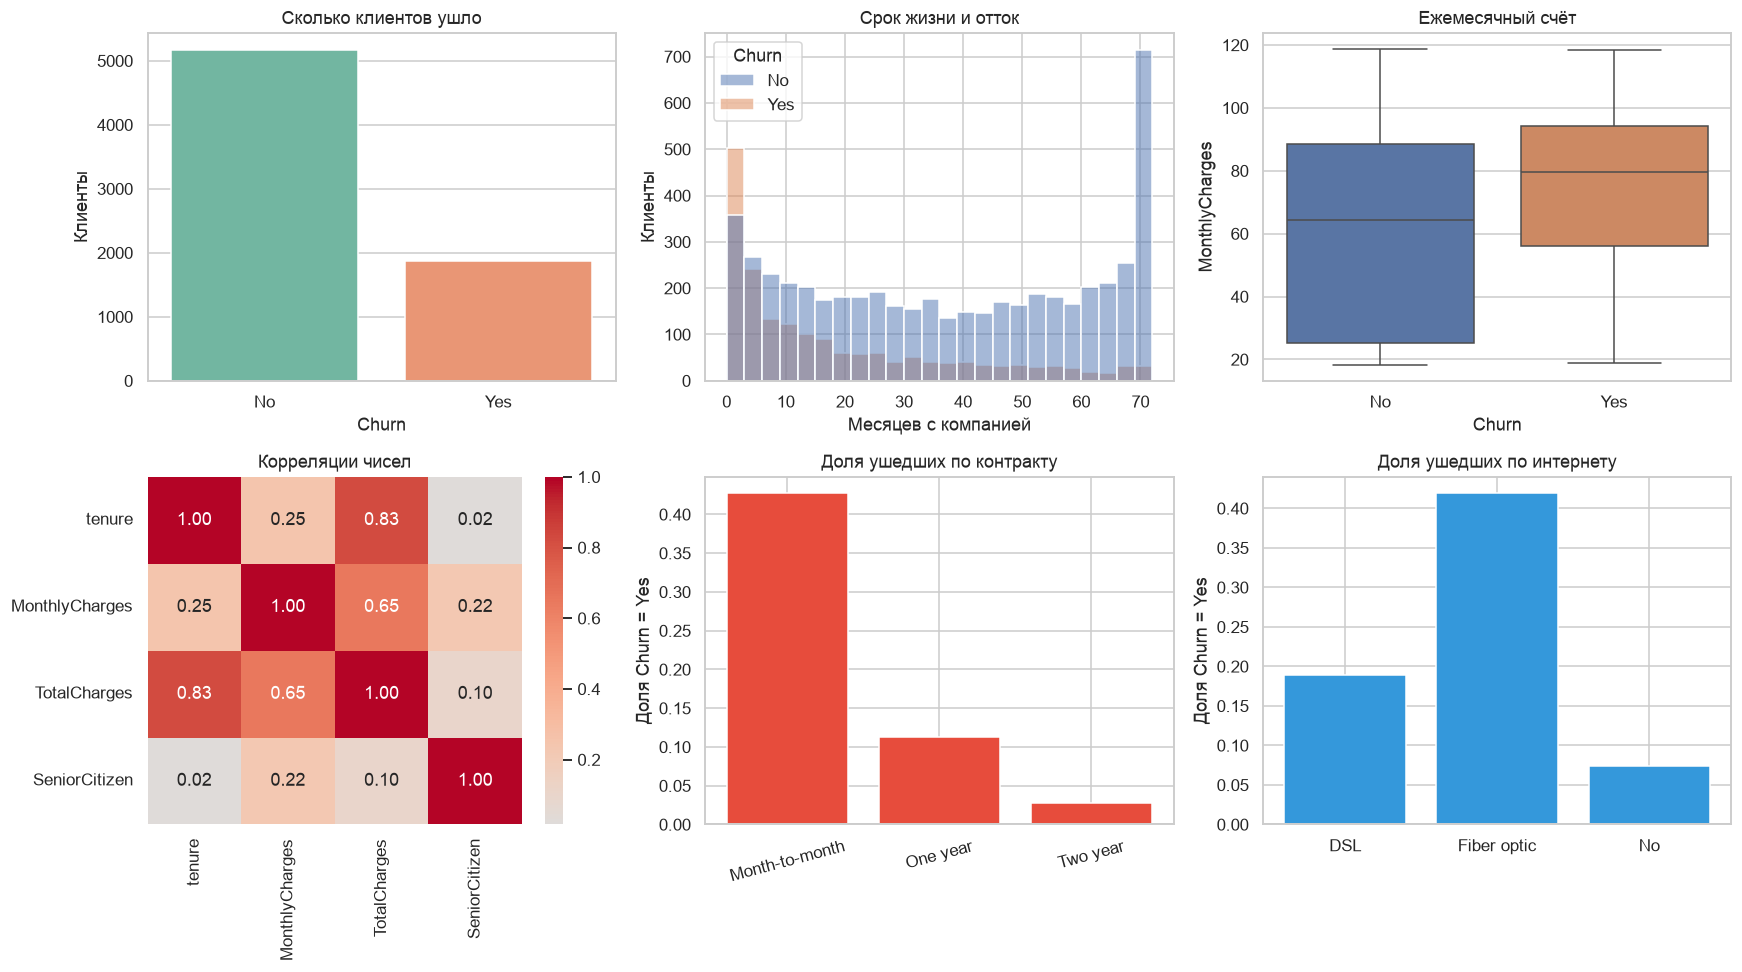

Отток при tenure <= 6: 0.529


In [3]:
fig, axes = plt.subplots(2, 3, figsize=(16, 9))

sns.countplot(data=df, x='Churn', hue='Churn', palette='Set2', legend=False, ax=axes[0, 0])
axes[0, 0].set_title('Сколько клиентов ушло')
axes[0, 0].set_xlabel('Churn')
axes[0, 0].set_ylabel('Клиенты')

sns.histplot(data=df, x='tenure', hue='Churn', bins=24, ax=axes[0, 1])
axes[0, 1].set_title('Срок жизни и отток')
axes[0, 1].set_xlabel('Месяцев с компанией')
axes[0, 1].set_ylabel('Клиенты')

sns.boxplot(data=df, x='Churn', y='MonthlyCharges', hue='Churn', legend=False, ax=axes[0, 2])
axes[0, 2].set_title('Ежемесячный счёт')
axes[0, 2].set_xlabel('Churn')
axes[0, 2].set_ylabel('MonthlyCharges')

corr_cols = ['tenure', 'MonthlyCharges', 'TotalCharges', 'SeniorCitizen']
sns.heatmap(df[corr_cols].corr(), annot=True, fmt='.2f', cmap='coolwarm', center=0, ax=axes[1, 0])
axes[1, 0].set_title('Корреляции чисел')

contract_rate = df.groupby('Contract')['Churn'].apply(lambda s: (s == 'Yes').mean()).reindex(['Month-to-month', 'One year', 'Two year'])
axes[1, 1].bar(contract_rate.index, contract_rate.values, color='#e74c3c')
axes[1, 1].set_title('Доля ушедших по контракту')
axes[1, 1].set_ylabel('Доля Churn = Yes')
axes[1, 1].tick_params(axis='x', rotation=15)

net_rate = df.groupby('InternetService')['Churn'].apply(lambda s: (s == 'Yes').mean())
axes[1, 2].bar(net_rate.index, net_rate.values, color='#3498db')
axes[1, 2].set_title('Доля ушедших по интернету')
axes[1, 2].set_ylabel('Доля Churn = Yes')

fig.tight_layout()
Path('examples').mkdir(exist_ok=True)
fig.savefig('examples/eda_plots.png', bbox_inches='tight')
plt.show()
print('Отток при tenure <= 6:', round(df.loc[df['tenure'] <= 6, 'Churn'].eq('Yes').mean(), 3))


### Что видно до модели

- Ушедших заметно меньше. Модель, которая никого не считает ушедшим, уже выглядит точной.
- В первые месяцы гистограмма tenure у класса Yes высокая. Среди тех, кто с компанией не дольше полугода, уходит 52.9%.
- Месячный контракт: отток 42.7%. Контракт на год: 11.3%. На два года: 2.8%. Это самый резкий срез в таблице.
- Fiber optic уходит в 41.9% случаев, DSL — в 19%, без интернета — в 7.4%. Волокно дороже, и это видно по ящику MonthlyCharges.
- `tenure` и `TotalCharges` сильно связаны: кто дольше платит, тот накопил большую сумму. Оба столбца в модель попадут, но трактовать их как два независимых эффекта нельзя.


In [4]:
# Стаж в годах и средний чек за месяц жизни. +1 в знаменателе спасает новых клиентов
df['TenureYears'] = df['tenure'] / 12
df['AvgMonthlyCharge'] = df['TotalCharges'] / (df['tenure'] + 1)
df['IsNewClient'] = (df['tenure'] <= 6).astype(int)

service_cols = [
    'PhoneService', 'MultipleLines', 'InternetService', 'OnlineSecurity',
    'OnlineBackup', 'DeviceProtection', 'TechSupport', 'StreamingTV', 'StreamingMovies',
]
absent = {'No', 'No internet service', 'No phone service'}
df['HasMultipleServices'] = df[service_cols].apply(lambda row: sum(str(v) not in absent for v in row), axis=1)

# Цель в 0/1 до кодирования остальных текстов
df['Churn'] = (df['Churn'] == 'Yes').astype(int)

label_encoders = {}
cat_cols = [c for c in df.columns if pd.api.types.is_string_dtype(df[c]) or df[c].dtype == object]
for col in cat_cols:
    encoder = LabelEncoder()
    df[col] = encoder.fit_transform(df[col].astype(str))
    label_encoders[col] = encoder
print('Закодировано столбцов:', cat_cols)

feature_cols = [c for c in df.columns if c not in ['customerID', 'Churn']]
X = df[feature_cols].astype(float)
y = df['Churn']
print(X.shape, 'доля класса 1:', round(float(y.mean()), 3))


Закодировано столбцов: ['customerID', 'gender', 'Partner', 'Dependents', 'PhoneService', 'MultipleLines', 'InternetService', 'OnlineSecurity', 'OnlineBackup', 'DeviceProtection', 'TechSupport', 'StreamingTV', 'StreamingMovies', 'Contract', 'PaperlessBilling', 'PaymentMethod']
(7043, 23) доля класса 1: 0.265


### Зачем так чистить и собирать признаки

- **`TotalCharges`.** Одиннадцать пустых строк — это клиенты с `tenure = 0`. Медиана не идеальна (у них скорее ноль), но дыр слишком мало, чтобы сдвинуть модель. Перевод в число обязателен, иначе столбец останется текстом.
- **`TenureYears`** — тот же стаж в более спокойной шкале. **`IsNewClient`** отдельно помечает первые полгода, потому что риск там скачет, а не растёт линейно.
- **`AvgMonthlyCharge`** отделяет «много платил, потому что долго живёт» от «много платит каждый месяц».
- **`HasMultipleServices`** считает подключённые услуги и не путает «нет интернета» с отдельным продуктом.
- Категории сжаты LabelEncoder, чтобы лес и три бустинга видели одну числовую матрицу. Для контракта порядок кодов случайный, поэтому важность контракта потом читается по SHAP, а не по величине кода.


## Построение и обучение моделей

Четыре ансамбля. Лес и LightGBM получают `class_weight='balanced'`, XGBoost — `scale_pos_weight=3`, CatBoost — `auto_class_weights='Balanced'`. Это один и тот же смысл: ушедший клиент весит больше. Разбиение стратифицированное, 80/20, `random_state=42`. Деревьям масштаб не нужен. Scaler всё равно учится и сохраняется: так линейную модель можно будет добавить на ту же матрицу.


In [5]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y,
)
print('Обучение:', len(X_train), 'тест:', len(X_test), 'доля 1 в тесте:', round(float(y_test.mean()), 3))
scaler = StandardScaler().fit(X_train)

rf_model = RandomForestClassifier(
    n_estimators=200, max_depth=10, class_weight='balanced', random_state=42, n_jobs=1,
)
start = time.time(); rf_model.fit(X_train, y_train); rf_time = time.time() - start

xgb_model = XGBClassifier(
    n_estimators=200, max_depth=6, learning_rate=0.1,
    subsample=0.9, colsample_bytree=0.9, scale_pos_weight=3,
    random_state=42, eval_metric='logloss', n_jobs=1,
)
start = time.time(); xgb_model.fit(X_train, y_train); xgb_time = time.time() - start

lgbm_model = LGBMClassifier(
    n_estimators=200, num_leaves=31, max_depth=7, learning_rate=0.05,
    class_weight='balanced', random_state=42, verbose=-1, n_jobs=1,
)
start = time.time(); lgbm_model.fit(X_train, y_train); lgbm_time = time.time() - start

cat_model = CatBoostClassifier(
    iterations=200, depth=6, learning_rate=0.1,
    auto_class_weights='Balanced', random_state=42, verbose=0,
)
start = time.time(); cat_model.fit(X_train, y_train); cat_time = time.time() - start

print(f'RF {rf_time:.3f} с, XGB {xgb_time:.3f} с, LGBM {lgbm_time:.3f} с, CatBoost {cat_time:.3f} с')


Обучение: 5634 тест: 1409 доля 1 в тесте: 0.265


RF 0.698 с, XGB 0.170 с, LGBM 0.122 с, CatBoost 0.452 с


На семи тысячах строк все четыре модели обучаются за секунды. CatBoost обычно самый долгий из четырёх, LightGBM самый короткий. Разница во времени здесь не повод выбирать модель: выборка маленькая.


## Оценка качества

Порог меток — 0.5, ROC-AUC считается по вероятности класса «уйдёт». Из-за весов классов recall по ушедшим будет выше, чем у модели без балансировки, а precision — ниже.


Random Forest
              precision    recall  f1-score   support

     остался       0.89      0.77      0.82      1035
        ушёл       0.54      0.75      0.62       374

    accuracy                           0.76      1409
   macro avg       0.71      0.76      0.72      1409
weighted avg       0.80      0.76      0.77      1409

XGBoost
              precision    recall  f1-score   support

     остался       0.88      0.78      0.83      1035
        ушёл       0.53      0.70      0.60       374

    accuracy                           0.76      1409
   macro avg       0.71      0.74      0.72      1409
weighted avg       0.79      0.76      0.77      1409

LightGBM
              precision    recall  f1-score   support

     остался       0.89      0.76      0.82      1035
        ушёл       0.53      0.75      0.62       374

    accuracy                           0.76      1409
   macro avg       0.71      0.76      0.72      1409
weighted avg       0.80      0.76      0.77

,Accuracy,Precision,Recall,F1,ROC-AUC,секунды
Модель,,,,,,
Random Forest,0.7608,0.5355,0.7460,0.6235,0.8388,0.6983
XGBoost,0.7587,0.5350,0.6952,0.6047,0.8277,0.1699
LightGBM,0.7594,0.5332,0.7513,0.6238,0.8377,0.1222
CatBoost,0.7537,0.5252,0.7513,0.6183,0.8365,0.4519


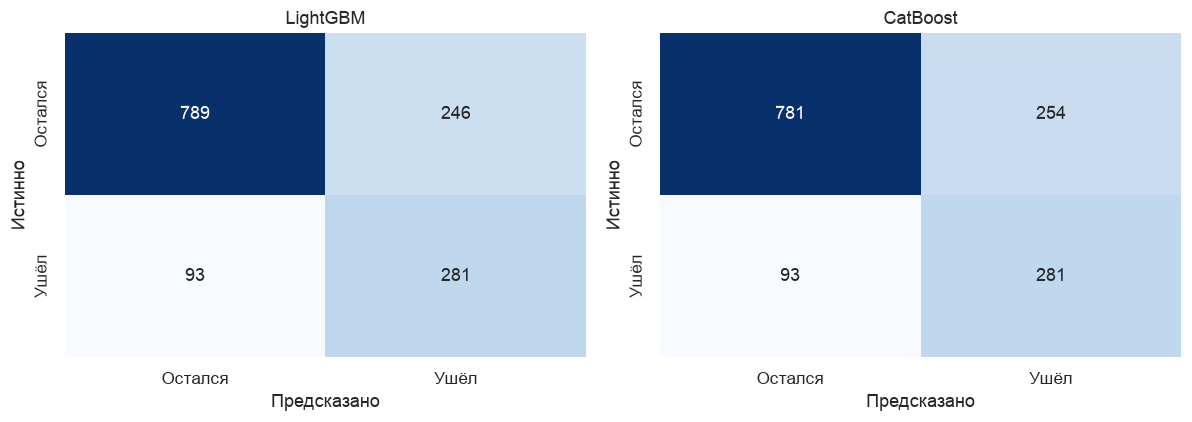

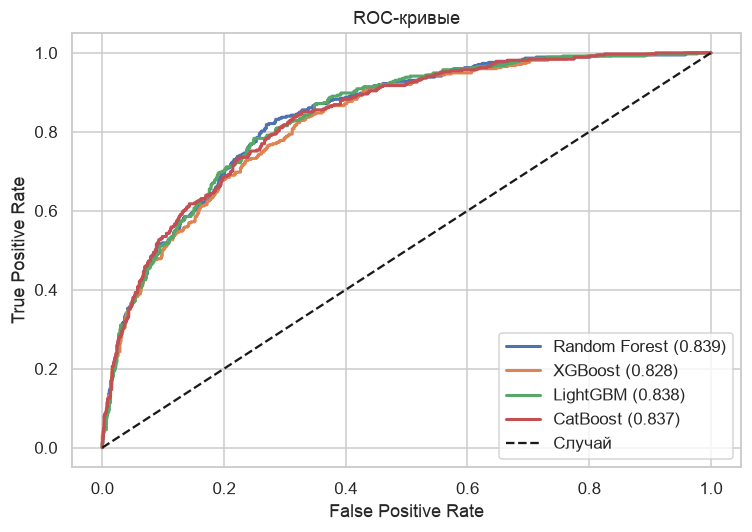

In [6]:
def evaluate(name, model, seconds):
    pred = model.predict(X_test)
    proba = model.predict_proba(X_test)[:, 1]
    print(name)
    print(classification_report(y_test, pred, target_names=['остался', 'ушёл']))
    return {
        'Модель': name,
        'Accuracy': accuracy_score(y_test, pred),
        'Precision': precision_score(y_test, pred),
        'Recall': recall_score(y_test, pred),
        'F1': f1_score(y_test, pred),
        'ROC-AUC': roc_auc_score(y_test, proba),
        'секунды': seconds,
    }, pred, proba

rows, preds, probas = [], {}, {}
for name, model, seconds in [
    ('Random Forest', rf_model, rf_time),
    ('XGBoost', xgb_model, xgb_time),
    ('LightGBM', lgbm_model, lgbm_time),
    ('CatBoost', cat_model, cat_time),
]:
    row, pred, proba = evaluate(name, model, seconds)
    rows.append(row)
    preds[name] = pred
    probas[name] = proba
metrics_table = pd.DataFrame(rows).set_index('Модель')
display(metrics_table.round(4))

fig, axes = plt.subplots(1, 2, figsize=(11, 4))
for ax, name in zip(axes, ['LightGBM', 'CatBoost']):
    cm = confusion_matrix(y_test, preds[name])
    sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', cbar=False, ax=ax,
                xticklabels=['Остался', 'Ушёл'], yticklabels=['Остался', 'Ушёл'])
    ax.set_xlabel('Предсказано')
    ax.set_ylabel('Истинно')
    ax.set_title(name)
fig.tight_layout()
plt.show()

fig, ax = plt.subplots(figsize=(7, 5))
for name, proba in probas.items():
    fpr, tpr, _ = roc_curve(y_test, proba)
    ax.plot(fpr, tpr, lw=2, label=f"{name} ({roc_auc_score(y_test, proba):.3f})")
ax.plot([0, 1], [0, 1], 'k--', label='Случай')
ax.set_xlabel('False Positive Rate')
ax.set_ylabel('True Positive Rate')
ax.set_title('ROC-кривые')
ax.legend()
fig.tight_layout()
fig.savefig('examples/roc_curves.png', bbox_inches='tight')
plt.show()


Чем выше ROC-AUC, тем лучше модель сортирует клиентов по риску ухода, даже если порог 0.5 потом сдвинуть. Балансировка классов поднимает recall: компания видит больше реальных уходов и одновременно звонит части тех, кто и так остался бы. Для удержания это обычно полезнее, чем молча терять клиентов. Точные цифры — в таблице над этим текстом.


## Интерпретация и бизнес-инсайты

Важность LightGBM — сколько раз признак улучшал дерево. Это не «на сколько процентов растёт отток», а очередность. Денежный смысл у срезов, которые уже посчитаны по сырой таблице.


,Feature,Importance
17,MonthlyCharges,1121
18,TotalCharges,1041
20,AvgMonthlyCharge,890
4,tenure,803
16,PaymentMethod,308
14,Contract,184
0,gender,167
15,PaperlessBilling,135
9,OnlineBackup,117
6,MultipleLines,110


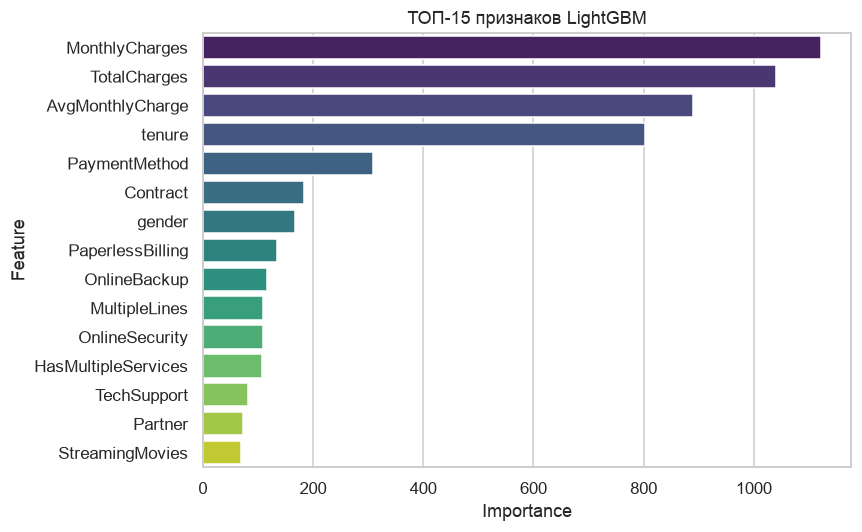

In [7]:
importances = pd.DataFrame({
    'Feature': feature_cols,
    'Importance': lgbm_model.feature_importances_,
}).sort_values('Importance', ascending=False)
display(importances.head(12))

fig, ax = plt.subplots(figsize=(8, 5))
sns.barplot(data=importances.head(15), x='Importance', y='Feature', hue='Feature', palette='viridis', legend=False, ax=ax)
ax.set_title('ТОП-15 признаков LightGBM')
fig.tight_layout()
fig.savefig('examples/feature_importance.png', bbox_inches='tight')
plt.show()


Контракт, стаж и платежи оказываются наверху почти у любого разреза этой таблицы, и модель это повторяет.

- Месячный контракт уходит в 3.8 раза чаще годового (42.7% против 11.3%) и в 15 раз чаще двухлетнего (2.8%).
- Первые 6 месяцев — зона риска: отток 52.9%. Флаг `IsNewClient` для того и собран.
- Fiber optic связан с оттоком 41.9%. Это не «волокно плохое», а дорогой тариф плюс месячный договор.
- `TotalCharges` частично дублирует tenure: долгая жизнь копит сумму. SHAP ниже показывает, не путает ли модель эти два столбца.


## Тюнинг гиперпараметров (Optuna)

Ищется LightGBM: 30 испытаний, внутри каждого — средний ROC-AUC на 5 стратифицированных фолдах обучающей выборки. Тест не участвует в поиске. Потом лучшие параметры один раз учиваются на всём обучении и сравниваются с базовым LightGBM на отложенных 20%.


In [8]:
def objective(trial):
    params = {
        'n_estimators': trial.suggest_int('n_estimators', 100, 500, step=50),
        'num_leaves': trial.suggest_int('num_leaves', 10, 100, step=5),
        'max_depth': trial.suggest_int('max_depth', 3, 12),
        'learning_rate': trial.suggest_float('learning_rate', 0.01, 0.3, log=True),
        'subsample': trial.suggest_float('subsample', 0.5, 1.0),
        'colsample_bytree': trial.suggest_float('colsample_bytree', 0.5, 1.0),
        'min_child_samples': trial.suggest_int('min_child_samples', 5, 50),
        'reg_alpha': trial.suggest_float('reg_alpha', 1e-3, 10, log=True),
        'reg_lambda': trial.suggest_float('reg_lambda', 1e-3, 10, log=True),
    }
    model = LGBMClassifier(**params, class_weight='balanced', random_state=42, verbose=-1, n_jobs=1)
    scores = cross_val_score(
        model, X_train, y_train,
        cv=StratifiedKFold(5, shuffle=True, random_state=42),
        scoring='roc_auc', n_jobs=1,
    )
    return float(scores.mean())

study = optuna.create_study(direction='maximize', sampler=optuna.samplers.TPESampler(seed=42))
study.optimize(objective, n_trials=30, show_progress_bar=False)
print('Лучший ROC-AUC на CV:', round(study.best_value, 4))
print(study.best_params)

best_lgbm = LGBMClassifier(**study.best_params, class_weight='balanced', random_state=42, verbose=-1, n_jobs=1)
start = time.time()
best_lgbm.fit(X_train, y_train)
best_time = time.time() - start
best_proba = best_lgbm.predict_proba(X_test)[:, 1]
best_pred = best_lgbm.predict(X_test)
base_auc = roc_auc_score(y_test, probas['LightGBM'])
best_auc = roc_auc_score(y_test, best_proba)
print(f'ROC-AUC baseline: {base_auc:.4f}')
print(f'ROC-AUC Optuna:   {best_auc:.4f}')
print(f'F1 Optuna: {f1_score(y_test, best_pred):.4f}')


Лучший ROC-AUC на CV: 0.8495
{'n_estimators': 500, 'num_leaves': 95, 'max_depth': 3, 'learning_rate': 0.014027974781468099, 'subsample': 0.6012562573207031, 'colsample_bytree': 0.5074160759021488, 'min_child_samples': 27, 'reg_alpha': 0.0012406307187657378, 'reg_lambda': 2.76662179284185}


ROC-AUC baseline: 0.8377
ROC-AUC Optuna:   0.8470
F1 Optuna: 0.6237


Тридцать испытаний смотрят обучающую выборку через кросс-валидацию. Прирост на тесте может быть меньше, чем на CV: тест модель не видела, и базовый LightGBM уже близок к потолку этой таблицы. Если Optuna не обгоняет базу на сотых долях AUC, это не провал поиска, а знак, что контракт и стаж уже выжаты простыми настройками.


## Интерпретация через SHAP

Explainer строится по модели после Optuna. Summary считается на тестовой выборке и показывает, в какую сторону каждый признак толкает логарифм шансов ухода. Waterfall разбирает одного клиента с самой высокой вероятностью ухода.


/Users/Pankyxa/projects/ML_Spirin/.venv/lib/python3.12/site-packages/shap/explainers/_tree.py:578: UserWarning: LightGBM binary classifier with TreeExplainer shap values output has changed to a list of ndarray
  warnings.warn(


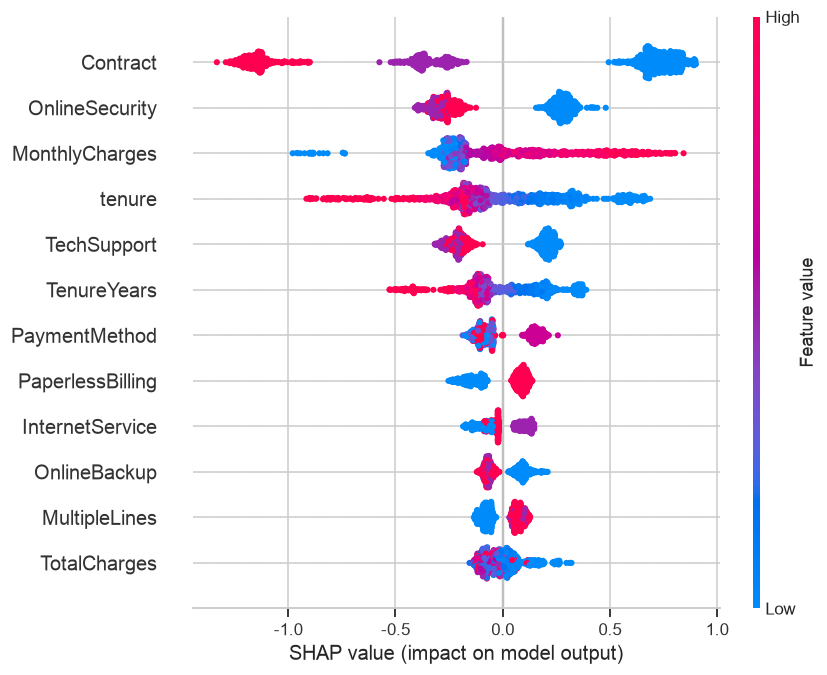

Клиент с максимальным риском, вероятность: 0.955
{'gender': 1.0, 'SeniorCitizen': 1.0, 'Partner': 1.0, 'Dependents': 0.0, 'tenure': 1.0, 'PhoneService': 1.0, 'MultipleLines': 2.0, 'InternetService': 1.0, 'OnlineSecurity': 0.0, 'OnlineBackup': 0.0, 'DeviceProtection': 0.0, 'TechSupport': 0.0, 'StreamingTV': 2.0, 'StreamingMovies': 2.0, 'Contract': 0.0, 'PaperlessBilling': 1.0, 'PaymentMethod': 2.0, 'MonthlyCharges': 95.1, 'TotalCharges': 95.1, 'TenureYears': 0.08333333333333333, 'AvgMonthlyCharge': 47.55, 'IsNewClient': 1.0, 'HasMultipleServices': 5.0}


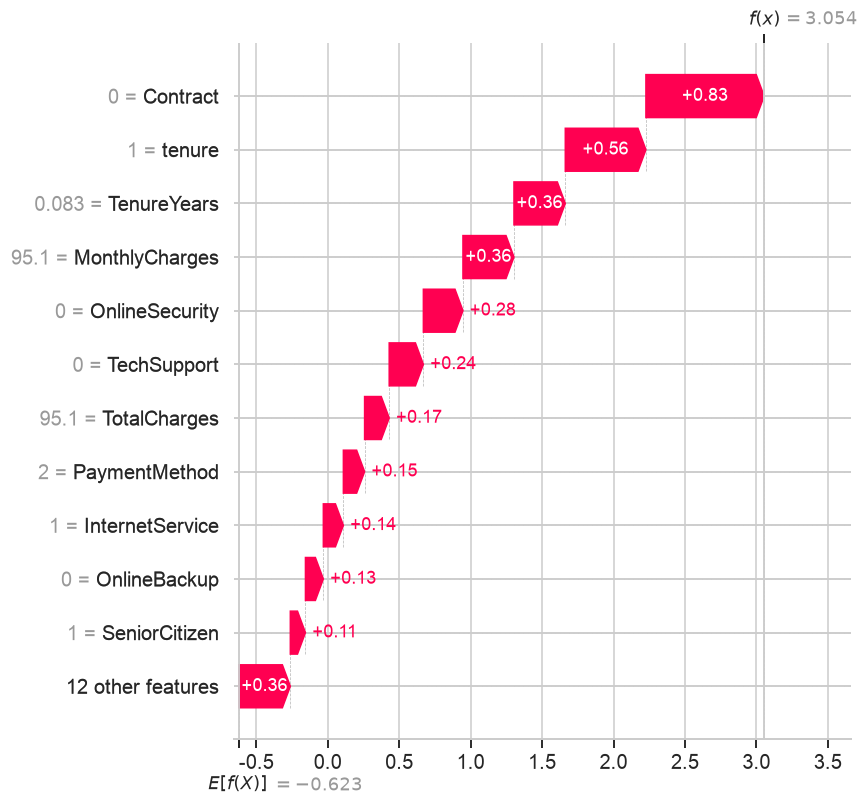

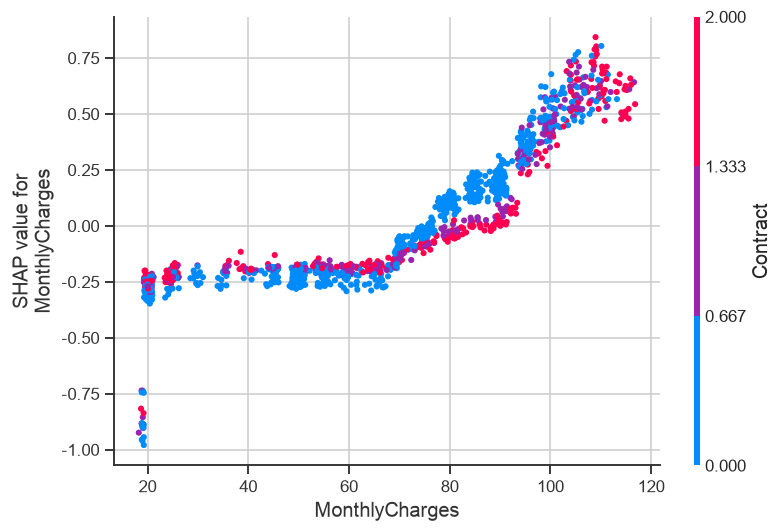

Dependence plot для MonthlyCharges


In [9]:
explainer = shap.TreeExplainer(best_lgbm)
raw_values = explainer.shap_values(X_test)
if isinstance(raw_values, list):
    shap_values = np.asarray(raw_values[1])
else:
    shap_values = np.asarray(raw_values)
if shap_values.ndim == 3:
    shap_values = shap_values[:, :, 1]

base_value = explainer.expected_value
if isinstance(base_value, (list, np.ndarray)):
    base_arr = np.asarray(base_value).reshape(-1)
    base_value = float(base_arr[1] if base_arr.size > 1 else base_arr[0])
else:
    base_value = float(base_value)

plt.figure()
shap.summary_plot(shap_values, X_test, show=False, max_display=12)
plt.tight_layout()
plt.savefig('examples/shap_summary.png', bbox_inches='tight')
plt.show()

worst_idx = int(np.argmax(best_proba))
print('Клиент с максимальным риском, вероятность:', round(float(best_proba[worst_idx]), 4))
print(X_test.iloc[worst_idx].to_dict())
explanation = shap.Explanation(
    values=shap_values[worst_idx],
    base_values=base_value,
    data=X_test.iloc[worst_idx].values,
    feature_names=list(X_test.columns),
)
plt.figure()
shap.plots.waterfall(explanation, show=False, max_display=12)
plt.tight_layout()
plt.savefig('examples/shap_waterfall.png', bbox_inches='tight')
plt.show()

top_feature = importances.iloc[0]['Feature']
shap.dependence_plot(top_feature, shap_values, X_test, show=False)
plt.tight_layout()
plt.show()
print('Dependence plot для', top_feature)


Summary plot подтверждает сырые доли, а не подменяет их. Короткий tenure и месячный контракт сдвигают прогноз к уходу. Защитные услуги (`OnlineSecurity`, `TechSupport`) сдвигают в обратную сторону, когда они реально подключены, а не стоят как «нет интернета». Высокий ежемесячный счёт сам по себе не приговор: он опасен вместе с коротким стажем и волокном.

Waterfall для самого рискованного клиента собирает тот же набор: тип контракта, маленький tenure и дорогой интернет дают плюс к риску, длинная история платежей — минус. Это уже повод для сценария удержания, а не только для таблицы метрик.


## Сохранение модели

Базовые четыре модели, модель после Optuna (`best_model.pkl`), scaler, словарь LabelEncoder, список признаков и метрики.


In [10]:
Path('models').mkdir(exist_ok=True)
joblib.dump(rf_model, 'models/rf_model.pkl')
joblib.dump(xgb_model, 'models/xgb_model.pkl')
joblib.dump(lgbm_model, 'models/lgbm_model.pkl')
joblib.dump(cat_model, 'models/cat_model.pkl')
joblib.dump(best_lgbm, 'models/best_model.pkl')
joblib.dump(scaler, 'models/scaler.pkl')
joblib.dump(label_encoders, 'models/label_encoders.pkl')
with open('models/feature_cols.json', 'w', encoding='utf-8') as file:
    json.dump(feature_cols, file, ensure_ascii=False, indent=2)

metrics = {}
for _, item in metrics_table.reset_index().iterrows():
    key = item['Модель'].lower().replace(' ', '_')
    metrics[key] = {col: float(item[col]) for col in ['Accuracy', 'Precision', 'Recall', 'F1', 'ROC-AUC', 'секунды']}
metrics['lightgbm_optuna'] = {
    'roc_auc': float(best_auc),
    'f1': float(f1_score(y_test, best_pred)),
    'accuracy': float(accuracy_score(y_test, best_pred)),
    'cv_roc_auc': float(study.best_value),
    'train_time_sec': float(best_time),
    'params': {k: (float(v) if isinstance(v, float) else int(v)) for k, v in study.best_params.items()},
}
with open('models/metrics.json', 'w', encoding='utf-8') as file:
    json.dump(metrics, file, indent=2)
print('Модели сохранены')


Модели сохранены


## Загрузка модели из репозитория

Проверка читает `best_model.pkl` по raw-ссылке. Если репозиторий ещё не опубликован, берётся локальный файл. Вероятность ухода для первой строки теста должна совпасть.


In [11]:
BASE_URL = 'https://raw.githubusercontent.com/Pankyxa/ML_Spirin/main/module-3-churn'

def load_joblib(relative_path):
    url = f'{BASE_URL}/{relative_path}'
    try:
        response = requests.get(url, timeout=15)
        response.raise_for_status()
        print('Из репозитория:', relative_path)
        return joblib.load(BytesIO(response.content))
    except Exception as error:
        print(f'Репозиторий недоступен ({error}). Локальный {relative_path}')
        return joblib.load(relative_path)

loaded = load_joblib('models/best_model.pkl')
sample = X_test.iloc[[0]]
p_now = float(best_lgbm.predict_proba(sample)[0, 1])
p_loaded = float(loaded.predict_proba(sample)[0, 1])
print('В памяти:', round(p_now, 6), 'загружено:', round(p_loaded, 6), 'совпало:', abs(p_now - p_loaded) < 1e-6)


Репозиторий недоступен (404 Client Error: Not Found for url: https://raw.githubusercontent.com/Pankyxa/ML_Spirin/main/module-3-churn/models/best_model.pkl). Локальный models/best_model.pkl
В памяти: 0.061599 загружено: 0.061599 совпало: True


## Выводы

### Что получилось

- Четыре ансамбля отделяют уход лучше константы «все останутся». ROC-AUC базовых моделей лежит около 0.84 и сравнивается в таблице раздела оценки.
- Optuna прогнала 30 испытаний по ROC-AUC на кросс-валидации. Итоговая модель сохранена как `best_model.pkl`.
- Контракт и первые месяцы жизни клиента важнее пола и способа оплаты. Это видно и по долям в сырых данных, и по SHAP.
- Балансировка классов подняла внимание к меньшему классу: ушедших 26.5%, без весов модель прятала бы их внутри accuracy.

### Трудности

- `TotalCharges` хранится текстом, у новых клиентов там пустая строка.
- Классы смещены 73.5 / 26.5. Высокая accuracy ничего не доказывает.
- LabelEncoder задаёт контракту ложный порядок чисел. Для деревьев расщепление это переживает, для линейной модели так делать нельзя.
- `tenure` и `TotalCharges` дублируют друг друга.
- Поиск Optuna легко переоценивает крошечный прирост, которого на новом тесте уже нет.

### Возможные улучшения

1. Кодировать контракт и интернет порядком или one-hot, а не случайными кодами LabelEncoder.
2. Подбирать порог по стоимости удержания, а не оставлять 0.5.
3. Добавить стекинг леса и бустинга.
4. Проверить, не течёт ли стаж в `TotalCharges` так сильно, что один из столбцов можно убрать.
5. Считать экономику: сколько стоит ложный звонок и сколько стоит потерянный клиент.


## Источники

1. Géron, A. (2022). *Hands-On Machine Learning with Scikit-Learn, Keras, and TensorFlow* (3rd ed.). O'Reilly Media.
2. Chen, T., Guestrin, C. (2016). XGBoost: A Scalable Tree Boosting System. KDD.
3. Ke, G. et al. (2017). LightGBM: A Highly Efficient Gradient Boosting Decision Tree. NeurIPS.
4. Prokhorenkova, L. et al. (2018). CatBoost: unbiased boosting with categorical features. NeurIPS.
5. Lundberg, S., Lee, S.-I. (2017). A Unified Approach to Interpreting Model Predictions. NeurIPS.
6. Kaggle. Telco Customer Churn. https://www.kaggle.com/datasets/blastchar/telco-customer-churn
7. Optuna documentation. https://optuna.readthedocs.io/


## Приложение

Зависимости — в `module-3-churn/requirements.txt`. Полный код ячеек:


```python
# %% ячейка 1
%matplotlib inline

import json
import time
from io import BytesIO
from pathlib import Path

import joblib
import matplotlib.pyplot as plt
import numpy as np
import optuna
import pandas as pd
import requests
import seaborn as sns
import shap
from IPython.display import display
from catboost import CatBoostClassifier
from lightgbm import LGBMClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (
    accuracy_score, classification_report, confusion_matrix,
    f1_score, precision_score, recall_score, roc_auc_score, roc_curve,
)
from sklearn.model_selection import StratifiedKFold, cross_val_score, train_test_split
from sklearn.preprocessing import LabelEncoder, StandardScaler
from xgboost import XGBClassifier

optuna.logging.set_verbosity(optuna.logging.WARNING)
sns.set_theme(style='whitegrid')
plt.rcParams['figure.dpi'] = 110
plt.rcParams['axes.unicode_minus'] = False

df = pd.read_csv('data/telco_churn.csv')
print(df.shape)
display(df.head())
print(df['Churn'].value_counts())
print((df['Churn'].value_counts(normalize=True) * 100).round(1))

# %% ячейка 2
display(df.info())
display(df.describe())

# Пробелы в TotalCharges становятся NaN, остальные строки — числа
df['TotalCharges'] = pd.to_numeric(df['TotalCharges'], errors='coerce')
missing = df.isnull().sum()
print('Пропуски после перевода TotalCharges:')
print(missing[missing > 0])

# Медиана: пустых мало, и это новые клиенты с нулевым стажем, не «особый тариф»
df['TotalCharges'] = df['TotalCharges'].fillna(df['TotalCharges'].median())

# %% ячейка 3
fig, axes = plt.subplots(2, 3, figsize=(16, 9))

sns.countplot(data=df, x='Churn', hue='Churn', palette='Set2', legend=False, ax=axes[0, 0])
axes[0, 0].set_title('Сколько клиентов ушло')
axes[0, 0].set_xlabel('Churn')
axes[0, 0].set_ylabel('Клиенты')

sns.histplot(data=df, x='tenure', hue='Churn', bins=24, ax=axes[0, 1])
axes[0, 1].set_title('Срок жизни и отток')
axes[0, 1].set_xlabel('Месяцев с компанией')
axes[0, 1].set_ylabel('Клиенты')

sns.boxplot(data=df, x='Churn', y='MonthlyCharges', hue='Churn', legend=False, ax=axes[0, 2])
axes[0, 2].set_title('Ежемесячный счёт')
axes[0, 2].set_xlabel('Churn')
axes[0, 2].set_ylabel('MonthlyCharges')

corr_cols = ['tenure', 'MonthlyCharges', 'TotalCharges', 'SeniorCitizen']
sns.heatmap(df[corr_cols].corr(), annot=True, fmt='.2f', cmap='coolwarm', center=0, ax=axes[1, 0])
axes[1, 0].set_title('Корреляции чисел')

contract_rate = df.groupby('Contract')['Churn'].apply(lambda s: (s == 'Yes').mean()).reindex(['Month-to-month', 'One year', 'Two year'])
axes[1, 1].bar(contract_rate.index, contract_rate.values, color='#e74c3c')
axes[1, 1].set_title('Доля ушедших по контракту')
axes[1, 1].set_ylabel('Доля Churn = Yes')
axes[1, 1].tick_params(axis='x', rotation=15)

net_rate = df.groupby('InternetService')['Churn'].apply(lambda s: (s == 'Yes').mean())
axes[1, 2].bar(net_rate.index, net_rate.values, color='#3498db')
axes[1, 2].set_title('Доля ушедших по интернету')
axes[1, 2].set_ylabel('Доля Churn = Yes')

fig.tight_layout()
Path('examples').mkdir(exist_ok=True)
fig.savefig('examples/eda_plots.png', bbox_inches='tight')
plt.show()
print('Отток при tenure <= 6:', round(df.loc[df['tenure'] <= 6, 'Churn'].eq('Yes').mean(), 3))

# %% ячейка 4
# Стаж в годах и средний чек за месяц жизни. +1 в знаменателе спасает новых клиентов
df['TenureYears'] = df['tenure'] / 12
df['AvgMonthlyCharge'] = df['TotalCharges'] / (df['tenure'] + 1)
df['IsNewClient'] = (df['tenure'] <= 6).astype(int)

service_cols = [
    'PhoneService', 'MultipleLines', 'InternetService', 'OnlineSecurity',
    'OnlineBackup', 'DeviceProtection', 'TechSupport', 'StreamingTV', 'StreamingMovies',
]
absent = {'No', 'No internet service', 'No phone service'}
df['HasMultipleServices'] = df[service_cols].apply(lambda row: sum(str(v) not in absent for v in row), axis=1)

# Цель в 0/1 до кодирования остальных текстов
df['Churn'] = (df['Churn'] == 'Yes').astype(int)

label_encoders = {}
cat_cols = [c for c in df.columns if pd.api.types.is_string_dtype(df[c]) or df[c].dtype == object]
for col in cat_cols:
    encoder = LabelEncoder()
    df[col] = encoder.fit_transform(df[col].astype(str))
    label_encoders[col] = encoder
print('Закодировано столбцов:', cat_cols)

feature_cols = [c for c in df.columns if c not in ['customerID', 'Churn']]
X = df[feature_cols].astype(float)
y = df['Churn']
print(X.shape, 'доля класса 1:', round(float(y.mean()), 3))

# %% ячейка 5
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y,
)
print('Обучение:', len(X_train), 'тест:', len(X_test), 'доля 1 в тесте:', round(float(y_test.mean()), 3))
scaler = StandardScaler().fit(X_train)

rf_model = RandomForestClassifier(
    n_estimators=200, max_depth=10, class_weight='balanced', random_state=42, n_jobs=1,
)
start = time.time(); rf_model.fit(X_train, y_train); rf_time = time.time() - start

xgb_model = XGBClassifier(
    n_estimators=200, max_depth=6, learning_rate=0.1,
    subsample=0.9, colsample_bytree=0.9, scale_pos_weight=3,
    random_state=42, eval_metric='logloss', n_jobs=1,
)
start = time.time(); xgb_model.fit(X_train, y_train); xgb_time = time.time() - start

lgbm_model = LGBMClassifier(
    n_estimators=200, num_leaves=31, max_depth=7, learning_rate=0.05,
    class_weight='balanced', random_state=42, verbose=-1, n_jobs=1,
)
start = time.time(); lgbm_model.fit(X_train, y_train); lgbm_time = time.time() - start

cat_model = CatBoostClassifier(
    iterations=200, depth=6, learning_rate=0.1,
    auto_class_weights='Balanced', random_state=42, verbose=0,
)
start = time.time(); cat_model.fit(X_train, y_train); cat_time = time.time() - start

print(f'RF {rf_time:.3f} с, XGB {xgb_time:.3f} с, LGBM {lgbm_time:.3f} с, CatBoost {cat_time:.3f} с')

# %% ячейка 6
def evaluate(name, model, seconds):
    pred = model.predict(X_test)
    proba = model.predict_proba(X_test)[:, 1]
    print(name)
    print(classification_report(y_test, pred, target_names=['остался', 'ушёл']))
    return {
        'Модель': name,
        'Accuracy': accuracy_score(y_test, pred),
        'Precision': precision_score(y_test, pred),
        'Recall': recall_score(y_test, pred),
        'F1': f1_score(y_test, pred),
        'ROC-AUC': roc_auc_score(y_test, proba),
        'секунды': seconds,
    }, pred, proba

rows, preds, probas = [], {}, {}
for name, model, seconds in [
    ('Random Forest', rf_model, rf_time),
    ('XGBoost', xgb_model, xgb_time),
    ('LightGBM', lgbm_model, lgbm_time),
    ('CatBoost', cat_model, cat_time),
]:
    row, pred, proba = evaluate(name, model, seconds)
    rows.append(row)
    preds[name] = pred
    probas[name] = proba
metrics_table = pd.DataFrame(rows).set_index('Модель')
display(metrics_table.round(4))

fig, axes = plt.subplots(1, 2, figsize=(11, 4))
for ax, name in zip(axes, ['LightGBM', 'CatBoost']):
    cm = confusion_matrix(y_test, preds[name])
    sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', cbar=False, ax=ax,
                xticklabels=['Остался', 'Ушёл'], yticklabels=['Остался', 'Ушёл'])
    ax.set_xlabel('Предсказано')
    ax.set_ylabel('Истинно')
    ax.set_title(name)
fig.tight_layout()
plt.show()

fig, ax = plt.subplots(figsize=(7, 5))
for name, proba in probas.items():
    fpr, tpr, _ = roc_curve(y_test, proba)
    ax.plot(fpr, tpr, lw=2, label=f"{name} ({roc_auc_score(y_test, proba):.3f})")
ax.plot([0, 1], [0, 1], 'k--', label='Случай')
ax.set_xlabel('False Positive Rate')
ax.set_ylabel('True Positive Rate')
ax.set_title('ROC-кривые')
ax.legend()
fig.tight_layout()
fig.savefig('examples/roc_curves.png', bbox_inches='tight')
plt.show()

# %% ячейка 7
importances = pd.DataFrame({
    'Feature': feature_cols,
    'Importance': lgbm_model.feature_importances_,
}).sort_values('Importance', ascending=False)
display(importances.head(12))

fig, ax = plt.subplots(figsize=(8, 5))
sns.barplot(data=importances.head(15), x='Importance', y='Feature', hue='Feature', palette='viridis', legend=False, ax=ax)
ax.set_title('ТОП-15 признаков LightGBM')
fig.tight_layout()
fig.savefig('examples/feature_importance.png', bbox_inches='tight')
plt.show()

# %% ячейка 8
def objective(trial):
    params = {
        'n_estimators': trial.suggest_int('n_estimators', 100, 500, step=50),
        'num_leaves': trial.suggest_int('num_leaves', 10, 100, step=5),
        'max_depth': trial.suggest_int('max_depth', 3, 12),
        'learning_rate': trial.suggest_float('learning_rate', 0.01, 0.3, log=True),
        'subsample': trial.suggest_float('subsample', 0.5, 1.0),
        'colsample_bytree': trial.suggest_float('colsample_bytree', 0.5, 1.0),
        'min_child_samples': trial.suggest_int('min_child_samples', 5, 50),
        'reg_alpha': trial.suggest_float('reg_alpha', 1e-3, 10, log=True),
        'reg_lambda': trial.suggest_float('reg_lambda', 1e-3, 10, log=True),
    }
    model = LGBMClassifier(**params, class_weight='balanced', random_state=42, verbose=-1, n_jobs=1)
    scores = cross_val_score(
        model, X_train, y_train,
        cv=StratifiedKFold(5, shuffle=True, random_state=42),
        scoring='roc_auc', n_jobs=1,
    )
    return float(scores.mean())

study = optuna.create_study(direction='maximize', sampler=optuna.samplers.TPESampler(seed=42))
study.optimize(objective, n_trials=30, show_progress_bar=False)
print('Лучший ROC-AUC на CV:', round(study.best_value, 4))
print(study.best_params)

best_lgbm = LGBMClassifier(**study.best_params, class_weight='balanced', random_state=42, verbose=-1, n_jobs=1)
start = time.time()
best_lgbm.fit(X_train, y_train)
best_time = time.time() - start
best_proba = best_lgbm.predict_proba(X_test)[:, 1]
best_pred = best_lgbm.predict(X_test)
base_auc = roc_auc_score(y_test, probas['LightGBM'])
best_auc = roc_auc_score(y_test, best_proba)
print(f'ROC-AUC baseline: {base_auc:.4f}')
print(f'ROC-AUC Optuna:   {best_auc:.4f}')
print(f'F1 Optuna: {f1_score(y_test, best_pred):.4f}')

# %% ячейка 9
explainer = shap.TreeExplainer(best_lgbm)
raw_values = explainer.shap_values(X_test)
if isinstance(raw_values, list):
    shap_values = np.asarray(raw_values[1])
else:
    shap_values = np.asarray(raw_values)
if shap_values.ndim == 3:
    shap_values = shap_values[:, :, 1]

base_value = explainer.expected_value
if isinstance(base_value, (list, np.ndarray)):
    base_arr = np.asarray(base_value).reshape(-1)
    base_value = float(base_arr[1] if base_arr.size > 1 else base_arr[0])
else:
    base_value = float(base_value)

plt.figure()
shap.summary_plot(shap_values, X_test, show=False, max_display=12)
plt.tight_layout()
plt.savefig('examples/shap_summary.png', bbox_inches='tight')
plt.show()

worst_idx = int(np.argmax(best_proba))
print('Клиент с максимальным риском, вероятность:', round(float(best_proba[worst_idx]), 4))
print(X_test.iloc[worst_idx].to_dict())
explanation = shap.Explanation(
    values=shap_values[worst_idx],
    base_values=base_value,
    data=X_test.iloc[worst_idx].values,
    feature_names=list(X_test.columns),
)
plt.figure()
shap.plots.waterfall(explanation, show=False, max_display=12)
plt.tight_layout()
plt.savefig('examples/shap_waterfall.png', bbox_inches='tight')
plt.show()

top_feature = importances.iloc[0]['Feature']
shap.dependence_plot(top_feature, shap_values, X_test, show=False)
plt.tight_layout()
plt.show()
print('Dependence plot для', top_feature)

# %% ячейка 10
Path('models').mkdir(exist_ok=True)
joblib.dump(rf_model, 'models/rf_model.pkl')
joblib.dump(xgb_model, 'models/xgb_model.pkl')
joblib.dump(lgbm_model, 'models/lgbm_model.pkl')
joblib.dump(cat_model, 'models/cat_model.pkl')
joblib.dump(best_lgbm, 'models/best_model.pkl')
joblib.dump(scaler, 'models/scaler.pkl')
joblib.dump(label_encoders, 'models/label_encoders.pkl')
with open('models/feature_cols.json', 'w', encoding='utf-8') as file:
    json.dump(feature_cols, file, ensure_ascii=False, indent=2)

metrics = {}
for _, item in metrics_table.reset_index().iterrows():
    key = item['Модель'].lower().replace(' ', '_')
    metrics[key] = {col: float(item[col]) for col in ['Accuracy', 'Precision', 'Recall', 'F1', 'ROC-AUC', 'секунды']}
metrics['lightgbm_optuna'] = {
    'roc_auc': float(best_auc),
    'f1': float(f1_score(y_test, best_pred)),
    'accuracy': float(accuracy_score(y_test, best_pred)),
    'cv_roc_auc': float(study.best_value),
    'train_time_sec': float(best_time),
    'params': {k: (float(v) if isinstance(v, float) else int(v)) for k, v in study.best_params.items()},
}
with open('models/metrics.json', 'w', encoding='utf-8') as file:
    json.dump(metrics, file, indent=2)
print('Модели сохранены')

# %% ячейка 11
BASE_URL = 'https://raw.githubusercontent.com/Pankyxa/ML_Spirin/main/module-3-churn'

def load_joblib(relative_path):
    url = f'{BASE_URL}/{relative_path}'
    try:
        response = requests.get(url, timeout=15)
        response.raise_for_status()
        print('Из репозитория:', relative_path)
        return joblib.load(BytesIO(response.content))
    except Exception as error:
        print(f'Репозиторий недоступен ({error}). Локальный {relative_path}')
        return joblib.load(relative_path)

loaded = load_joblib('models/best_model.pkl')
sample = X_test.iloc[[0]]
p_now = float(best_lgbm.predict_proba(sample)[0, 1])
p_loaded = float(loaded.predict_proba(sample)[0, 1])
print('В памяти:', round(p_now, 6), 'загружено:', round(p_loaded, 6), 'совпало:', abs(p_now - p_loaded) < 1e-6)
```
